# Завдання 7. Стійкість до шуму і вибору запиту; точність і час розрахунку

**Пункт 7 ТЗ.** Оцінити чутливість і стійкість моделі до шуму в ребрах (видалення справжніх і додавання хибних зв'язків) та до вибору вузлів запиту, а також порівняти точність і час розрахунку для трьох способів (ітерація, розв'язання лінійної системи, матрична експонента).

**Правила:**
- **Параметри не перепідбираємо під шум.** Використовуємо варіанти, обрані раніше на окремих даних:
  - запити з одним вузлом на MetaQA — PPR, α = 0.5, сирі оцінки (п. 6);
  - SBM — теплове ядро, t = 7, π/√d (п. 6);
  - пари на MetaQA — теплове ядро, t = 1, π/√d, добуток (п. 5).
- **Правильні відповіді** завжди з чистого графа, ранжування — на зашумленому.
- **Нічиї базових методів:** головне порівняння з random-розбиттям; optimistic і pessimistic — додаткові межі.
- **Ізольовані запити.** Якщо вузол запиту став ізольованим (втратив усі ребра), такий запит виключаємо і показуємо, скільки їх.
- **Шум на синтетиці** — `graphs.perturb_edges`. **На MetaQA** — `metaqa.perturb_triples`: хибні трійки зі збереженням схеми KG (випадковий фільм, відношення r, випадковий об'єкт допустимого для r типу). Це модель помилки вилучення трійок.

In [1]:
from pathlib import Path
import time
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

from reldiff.api import rank
from reldiff.multi import combine_scores
from reldiff import graphs as G
from reldiff import metaqa as MQ
from reldiff import metrics as M
from reldiff import models

FIG = Path("../figures"); RES = Path("../results")
if False:   # швидка перевірка: вивід поза проєктом
    FIG = RES = Path("/tmp/reldiff_smoke/smoke07"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
TIES = ["random", "pessimistic", "optimistic"]
SMALL = False
NOISE_SEEDS = [0] if SMALL else [0, 1, 2]

def recall_at(scores, relevant, seeds, n, ties="random"):
    order = M.ranking(scores, relevant=set(relevant), seeds=seeds, ties=ties, seed=0)
    rel = set(relevant) - set(seeds)
    return len(rel & set(order[:n])) / len(rel)

def macro(df, by, metric):
    return df.groupby(by + ["qtype"])[metric].mean().groupby(by).mean()

def graph_from_triples(tr, all_nodes_graph):
    # граф з трійок + усі вузли чистого графа (ті, що втратили всі ребра, лишаються ізольованими)
    h = MQ.to_graph(tr)
    for v, k in all_nodes_graph.nodes(data="kinds"):
        if v not in h: h.add_node(v, kinds=k)
    return h

g0, Q0, P0 = MQ.load_processed("../data/metaqa", 500, 0)
trip0 = list(pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str,
                         keep_default_na=False).itertuples(index=False, name=None))
RARE = {"movie_to_imdbvotes", "movie_to_imdbrating"}
def strat(df, n, seed):
    r = np.random.default_rng(seed)
    return pd.concat([grp.iloc[np.sort(r.choice(len(grp), min(n, len(grp)), replace=False))]
                      for _, grp in df.groupby("qtype", sort=True)])
N_PER_QT = 3 if SMALL else 20
QS = strat(Q0[(Q0["split"] == "test") & ~Q0["qtype"].isin(RARE)], N_PER_QT, seed=7)
print(f"Питань MetaQA для 7.1: {len(QS)} (вузлів запиту {QS.topic.nunique()}), за hop: {QS.groupby('hop').size().to_dict()}")

Питань MetaQA для 7.1: 839 (вузлів запиту 636), за hop: {1: 203, 2: 369, 3: 267}


## Завдання 7.1. Шум у ребрах

### SBM (p_out = 0.005 — зона, де дифузія виграє, п. 6)

Видаляємо частку f ∈ {0.05, 0.1, 0.2, 0.3} справжніх ребер або додаємо таку саму частку хибних, плюс комбінація 0.1 + 0.1. Для кожного рівня — 3 seed шуму. Правильні відповіді — спільнота вузла запиту за чистим графом.

In [2]:
LEVELS = [("чистий", 0.0, 0.0)] + [(f"видалення {f}", f, 0.0) for f in (0.05, 0.1, 0.2, 0.3)] + \
         [(f"додавання {f}", 0.0, f) for f in (0.05, 0.1, 0.2, 0.3)] + [("видалення 0.1 + додавання 0.1", 0.1, 0.1)]
if SMALL: LEVELS = LEVELS[:2] + LEVELS[5:6]
g_sbm = G.sbm([200] * 5, 0.05, 0.005, seed=6)
comm = G.communities(g_sbm)
r = np.random.default_rng(2); nodes = list(g_sbm.nodes())
SBM_Q = [nodes[i] for i in r.choice(len(nodes), 10 if SMALL else 50, replace=False)]
SBM_BASE = [("найкор. шлях", dict(method="shortest_path")), ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
            ("k-hop, k=1", dict(method="k_hop", hops=1)), ("k-hop, k=2", dict(method="k_hop", hops=2)),
            ("k-hop, k=3", dict(method="k_hop", hops=3))]
rows, brows, iso = [], [], []
for lname, fr, fa in LEVELS:
    for ns in (NOISE_SEEDS if lname != "чистий" else [0]):
        gn = g_sbm if lname == "чистий" else G.perturb_edges(g_sbm, fr, fa, seed=100 + ns)[0]
        n_iso = 0
        for q in SBM_Q:
            if gn.degree(q) == 0:
                n_iso += 1; continue
            rel = comm[g_sbm.nodes[q]["community"]] - {q}
            sc = rank(gn, q, "heat", t=7.0, normalize="sqrt_degree")
            ev = M.evaluate(sc, rel, ks=(10, 50), seeds=[q])
            rows.append(dict(рівень=lname, seed=ns, метод="дифузія (теплове ядро, t=7, π/√d)", нічиї="random", **ev))
            for bname, kw in SBM_BASE:
                bs = rank(gn, q, **kw)
                for ties in TIES:
                    rows.append(dict(рівень=lname, seed=ns, метод=bname, нічиї=ties,
                                     **M.evaluate(bs, rel, ks=(10, 50), seeds=[q], ties=ties)))
            dist = nx.single_source_shortest_path_length(gn, q, cutoff=2)
            ball = {v for v, d in dist.items() if 0 < d <= 2}
            brows.append(dict(рівень=lname, seed=ns, N=len(ball), повнота_khop=len(rel & ball) / len(rel),
                              повнота_дифузії=recall_at(sc, rel, [q], len(ball))))
        iso.append(dict(рівень=lname, seed=ns, ізольованих_запитів=n_iso))
sbm_noise = pd.DataFrame(rows)
sbm_n = sbm_noise.groupby(["рівень", "метод", "нічиї"], sort=False)[["P@10", "nDCG@50"]].mean().reset_index()
sbm_n.to_csv(RES / "07_shum_sbm.csv", index=False)
sbm_b = pd.DataFrame(brows).groupby("рівень", sort=False)[["N", "повнота_khop", "повнота_дифузії"]].mean()
sbm_b.to_csv(RES / "07_shum_sbm_byudzhet_k2.csv")
print("Ізольовані запити (виключено):", pd.DataFrame(iso).groupby("рівень", sort=False)["ізольованих_запитів"].sum().to_dict())
display(sbm_n[sbm_n["нічиї"] == "random"].pivot_table(index="метод", columns="рівень", values="P@10", sort=False))
display(sbm_b)

Ізольовані запити (виключено): {'чистий': 0, 'видалення 0.05': 0, 'видалення 0.1': 0, 'видалення 0.2': 0, 'видалення 0.3': 0, 'додавання 0.05': 0, 'додавання 0.1': 0, 'додавання 0.2': 0, 'додавання 0.3': 0, 'видалення 0.1 + додавання 0.1': 0}


рівень,чистий,видалення 0.05,видалення 0.1,видалення 0.2,видалення 0.3,додавання 0.05,додавання 0.1,додавання 0.2,додавання 0.3,видалення 0.1 + додавання 0.1
метод,,,,,,,,,,
"дифузія (теплове ядро, t=7, π/√d)",0.896,0.873,0.861,0.819,0.805,0.895,0.886,0.857,0.825,0.829
найкор. шлях,0.760,0.755,0.746,0.729,0.730,0.736,0.709,0.671,0.632,0.699
схожість Σ|N(v)∩N(q)|,0.856,0.838,0.803,0.750,0.713,0.839,0.811,0.757,0.717,0.749
"k-hop, k=1",0.702,0.700,0.697,0.667,0.652,0.673,0.654,0.605,0.565,0.651
"k-hop, k=2",0.734,0.724,0.721,0.704,0.707,0.705,0.692,0.655,0.625,0.671
"k-hop, k=3",0.738,0.732,0.746,0.716,0.737,0.720,0.707,0.660,0.632,0.690


,N,повнота_khop,повнота_дифузії
рівень,,,
чистий,170.740,0.441,0.684
видалення 0.05,156.420,0.407,0.625
видалення 0.1,140.160,0.370,0.560
видалення 0.2,118.393,0.314,0.458
видалення 0.3,92.740,0.259,0.357
додавання 0.05,187.147,0.453,0.680
додавання 0.1,202.787,0.462,0.666
додавання 0.2,239.047,0.486,0.639
додавання 0.3,273.393,0.506,0.616


### MetaQA: шум у трійках KG

Рівні шуму: видалення {0.1, 0.2, 0.3}, додавання {0.1, 0.3} і комбінація 0.1 + 0.1, по 2 seed. До 20 test-питань на qtype. Базові методи в таблиці якості: найкоротший шлях, Σ-схожість, k-hop (k = 2); у таблиці бюджету — k = 1, 2, 3 (з тієї ж BFS). Метрики:
- макро-nDCG@10 за hop для обраного варіанта (PPR, α = 0.5, сирі) і базових методів;
- **таблиця бюджету k-hop з п. 6**, де N — розмір k-околу на **зашумленому** графі (GraphRAG бачить лише граф з шумом), а правильні відповіді — з чистого.

In [3]:
MQ_BASE = [("найкор. шлях", dict(method="shortest_path")), ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
           ("k-hop, k=2", dict(method="k_hop", hops=2))]
MQ_LEVELS = [("чистий", 0.0, 0.0)] + [(f"видалення {f}", f, 0.0) for f in (0.1, 0.2, 0.3)] + \
            [(f"додавання {f}", 0.0, f) for f in (0.1, 0.3)] + [("видалення 0.1 + додавання 0.1", 0.1, 0.1)]
MQ_SEEDS = NOISE_SEEDS[:2]
if SMALL: MQ_LEVELS = MQ_LEVELS[:2]

def run_mq(gn, Q, label, ns):
    rows, brows, n_iso, n_q = [], [], 0, 0
    for topic, grp in Q.groupby("topic", sort=False):
        if gn.degree(topic) == 0:
            n_iso += len(grp); continue
        dist = nx.single_source_shortest_path_length(gn, topic)
        sc = rank(gn, topic, "ppr", alpha=0.5)
        base = {b: rank(gn, topic, **kw) for b, kw in MQ_BASE}
        balls = {k: sum(1 for v, d in dist.items() if 0 < d <= k) for k in (1, 2, 3)}
        for qq in grp.itertuples():
            rel = set(qq.answers) - {topic}
            if not rel: continue
            n_q += 1
            meta = dict(рівень=label, seed=ns, hop=qq.hop, qtype=qq.qtype)
            rows.append(dict(**meta, метод="дифузія (PPR, α=0.5, сирі)", нічиї="random",
                             nDCG10=M.ndcg_at_k(sc, rel, 10, seeds=[topic]), RR=M.reciprocal_rank(sc, rel, seeds=[topic])))
            for b, bs in base.items():
                for ties in TIES:
                    rows.append(dict(**meta, метод=b, нічиї=ties, nDCG10=M.ndcg_at_k(bs, rel, 10, seeds=[topic], ties=ties),
                                     RR=M.reciprocal_rank(bs, rel, seeds=[topic], ties=ties)))
            for k in (1, 2, 3):
                rk = len([a for a in rel if dist.get(a, np.inf) <= k]) / len(rel)
                rd = recall_at(sc, rel, [topic], balls[k])
                brows.append(dict(**meta, k=k, N=balls[k], повнота_khop=rk, повнота_дифузії=rd,
                                  khop_0_дифузія_знаходить=(rk == 0) and (rd > 0)))
    return rows, brows, dict(рівень=label, seed=ns, ізольованих_питань=n_iso, оцінено_питань=n_q)

t0 = time.perf_counter()
mrows, mbrows, miso = [], [], []
for lname, fr, fa in MQ_LEVELS:
    for ns in (MQ_SEEDS if lname != "чистий" else [0]):
        if lname == "чистий":
            gn = g0
        else:
            tr, _ = MQ.perturb_triples(trip0, fr, fa, seed=200 + ns)
            gn = graph_from_triples(tr, g0)
        a, b, c = run_mq(gn, QS, lname, ns)
        mrows += a; mbrows += b; miso.append(c)
print(f"MetaQA, шум: {time.perf_counter() - t0:.0f} с")
mq_noise = pd.DataFrame(mrows); mq_bud = pd.DataFrame(mbrows)
print("Ізольовані запити (виключені питання):", pd.DataFrame(miso).groupby("рівень", sort=False)["ізольованих_питань"].sum().to_dict())
mq_n = macro(mq_noise, ["рівень", "метод", "нічиї", "hop"], "nDCG10").reset_index()
mq_n.to_csv(RES / "07_shum_metaqa.csv", index=False)
display(mq_n[mq_n["нічиї"] == "random"].pivot_table(index=["метод", "hop"], columns="рівень", values="nDCG10", sort=False))
mq_b = mq_bud.groupby(["рівень", "hop", "k"], sort=False).agg(N_медіана=("N", "median"), повнота_khop=("повнота_khop", "mean"),
                                                             повнота_дифузії=("повнота_дифузії", "mean"),
                                                             khop_0_дифузія_знаходить=("khop_0_дифузія_знаходить", "mean")).reset_index()
mq_b.to_csv(RES / "07_shum_metaqa_byudzhet.csv", index=False)
display(mq_b[(mq_b["hop"] == 3) & (mq_b["k"] == 2)])

MetaQA, шум: 1026 с
Ізольовані запити (виключені питання): {'чистий': 0, 'видалення 0.1': 54, 'видалення 0.2': 105, 'видалення 0.3': 166, 'додавання 0.1': 0, 'додавання 0.3': 0, 'видалення 0.1 + додавання 0.1': 47}


рівень                          видалення 0.1  видалення 0.1 + додавання 0.1  видалення 0.2  видалення 0.3  додавання 0.1  додавання 0.3  чистий
метод                      hop                                                                                                                  
k-hop, k=2                 1            0.679                          0.641          0.654          0.609          0.672          0.613   0.684
                           2            0.277                          0.230          0.260          0.254          0.248          0.176   0.288
                           3            0.097                          0.084          0.096          0.087          0.088          0.081   0.096
дифузія (PPR, α=0.5, сирі) 1            0.714                          0.689          0.698          0.642          0.725          0.692   0.744
                           2            0.325                          0.287          0.308          0.292          0.309          0.252   0.337
                           3            0.148                          0.146          0.132          0.128          0.161          0.163   0.158
найкор. шлях               1            0.665                          0.664          0.655          0.606          0.709          0.640   0.736
                           2            0.262                          0.236          0.255          0.246          0.238          0.167   0.276
                           3            0.087                          0.096          0.081          0.086          0.093          0.084   0.097
схожість Σ|N(v)∩N(q)|      1            0.001                          0.000          0.000          0.000          0.000          0.000   0.000
                           2            0.419                          0.391          0.396          0.376          0.403          0.333   0.443
                           3            0.001                          0.001          0.001          0.000          0.001          0.001   0.001

,рівень,hop,k,N_медіана,повнота_khop,повнота_дифузії,khop_0_дифузія_знаходить
7,чистий,3,2,174.000,0.162,0.552,0.386
16,видалення 0.1,3,2,102.500,0.147,0.440,0.335
25,видалення 0.2,3,2,74.000,0.131,0.364,0.313
34,видалення 0.3,3,2,56.500,0.128,0.299,0.236
43,додавання 0.1,3,2,179.000,0.164,0.538,0.376
52,додавання 0.3,3,2,195.000,0.167,0.517,0.354
61,видалення 0.1 + додавання 0.1,3,2,113.000,0.148,0.438,0.328


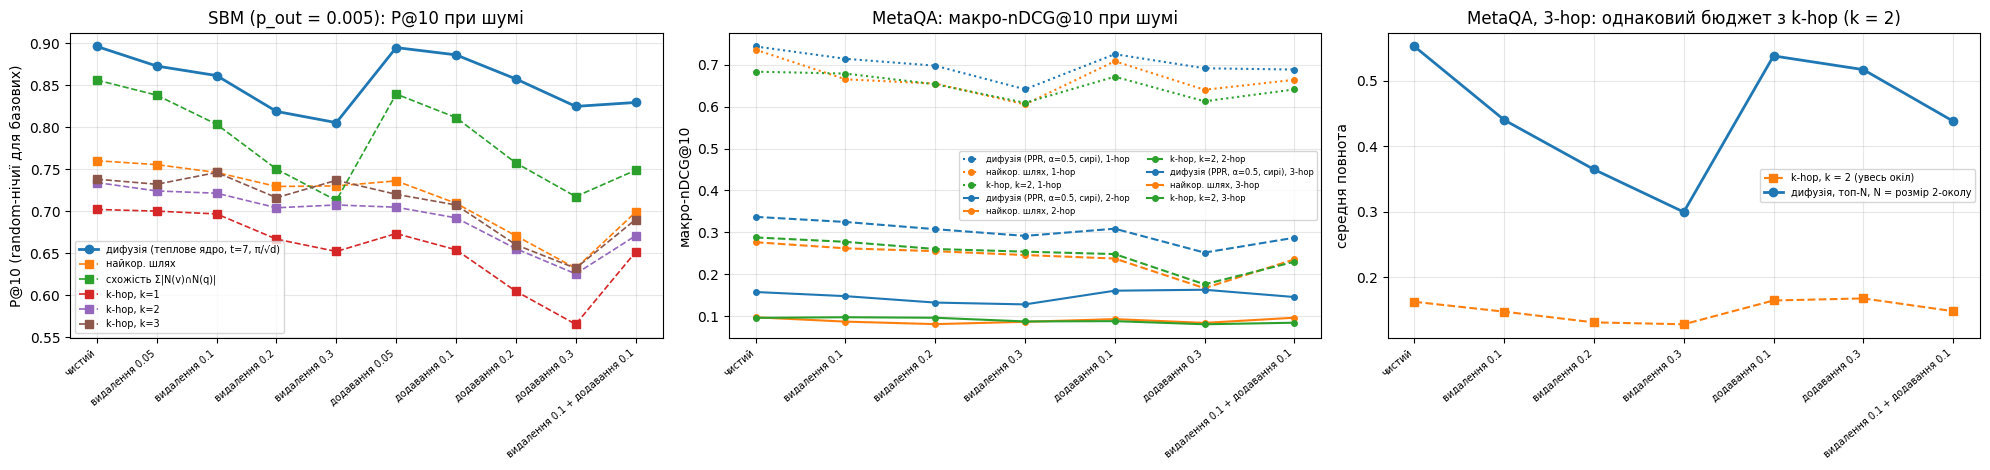

In [4]:
lv = [l for l, _, _ in LEVELS]; lvm = [l for l, _, _ in MQ_LEVELS]
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
sub = sbm_n[sbm_n["нічиї"] == "random"]
for i, m in enumerate(sub["метод"].unique()):
    y = sub[sub["метод"] == m].set_index("рівень")["P@10"].reindex(lv)
    axs[0].plot(range(len(lv)), y, "o-" if i == 0 else "s--", lw=2 if i == 0 else 1.2, label=m)
axs[0].set_title("SBM (p_out = 0.005): P@10 при шумі"); axs[0].set_ylabel("P@10 (random-нічиї для базових)")
for h, ls in ((1, ":"), (2, "--"), (3, "-")):
    for i, m in enumerate(["дифузія (PPR, α=0.5, сирі)", "найкор. шлях", "k-hop, k=2"]):
        s0 = mq_n[(mq_n["метод"] == m) & (mq_n["нічиї"] == "random") & (mq_n["hop"] == h)].set_index("рівень")["nDCG10"].reindex(lvm)
        axs[1].plot(range(len(lvm)), s0, ls, marker="o", ms=4, color=f"C{i}", label=f"{m}, {h}-hop")
axs[1].set_title("MetaQA: макро-nDCG@10 при шумі"); axs[1].set_ylabel("макро-nDCG@10")
s3 = mq_b[(mq_b["hop"] == 3) & (mq_b["k"] == 2)].set_index("рівень").reindex(lvm)
axs[2].plot(range(len(lvm)), s3["повнота_khop"], "s--", color="C1", label="k-hop, k = 2 (увесь окіл)")
axs[2].plot(range(len(lvm)), s3["повнота_дифузії"], "o-", color="C0", lw=2, label="дифузія, топ-N, N = розмір 2-околу")
axs[2].set_title("MetaQA, 3-hop: однаковий бюджет з k-hop (k = 2)"); axs[2].set_ylabel("середня повнота")
for ax, L in zip(axs, (lv, lvm, lvm)):
    ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=40, ha="right", fontsize=7); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7); axs[1].legend(fontsize=6, ncol=2); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "07_shum.png", dpi=200); plt.show()

## Завдання 7.2. Пари з п. 5 при видаленні ребер

Рекомендований варіант (теплове ядро, t = 1, π/√d, добуток) проти оракула — перетину 1-околів запитів. Пари ті самі, що в п. 5: до 300 кожного типу, seed = 0. Режими:
- **(а) цільове видалення:** кожне ребро «вузол запиту — спільний фільм» видаляємо з імовірністю f;
- **(б) глобальне видалення** частки f усіх трійок KG.

f ∈ {0, 0.1, 0.2, 0.3, 0.5}, 3 seed. Окремо для відповідей, які оракул втратив, — яку їх частку дифузія ставить у топ-1, топ-5 і топ-10.

Пари, де вузол запиту став ізольованим, показуємо у двох варіантах: (1) виключено; (2) враховано як MRR = 0 для обох методів.

Пари: 535 с
Пари з ізольованим вузлом запиту (виключено): {('глобальне', 0.0): 0, ('глобальне', 0.1): 186, ('глобальне', 0.2): 374, ('глобальне', 0.3): 501, ('глобальне', 0.5): 917, ('цільове', 0.0): 0, ('цільове', 0.1): 160, ('цільове', 0.2): 319, ('цільове', 0.3): 461, ('цільове', 0.5): 738}
Варіант 1 — ізольовані пари виключено:


,режим,f,kind,MRR_дифузії,MRR_оракула_random,MRR_оракула_pessimistic,MRR_оракула_optimistic,ізольованих,усього
0,глобальне,0.000,actor_actor,1.000,1.000,1.000,1.000,0,300
1,глобальне,0.000,actor_director,1.000,0.998,0.998,1.000,0,300
2,глобальне,0.100,actor_actor,0.957,0.915,0.915,0.915,97,900
3,глобальне,0.100,actor_director,0.964,0.923,0.923,0.925,89,900
4,глобальне,0.200,actor_actor,0.894,0.822,0.822,0.822,213,900
5,глобальне,0.200,actor_director,0.910,0.844,0.844,0.846,161,900
6,глобальне,0.300,actor_actor,0.808,0.708,0.708,0.708,264,900
7,глобальне,0.300,actor_director,0.858,0.766,0.766,0.766,237,900
8,глобальне,0.500,actor_actor,0.636,0.527,0.527,0.527,462,900
9,глобальне,0.500,actor_director,0.710,0.592,0.592,0.593,455,900


Варіант 2 — ізольовані пари враховано як MRR = 0 для обох методів:


,режим,f,kind,MRR_дифузії,MRR_оракула_random,MRR_оракула_pessimistic,MRR_оракула_optimistic
0,глобальне,0.000,actor_actor,1.000,1.000,1.000,1.000
1,глобальне,0.000,actor_director,1.000,0.998,0.998,1.000
2,глобальне,0.100,actor_actor,0.854,0.817,0.817,0.817
3,глобальне,0.100,actor_director,0.868,0.832,0.832,0.833
4,глобальне,0.200,actor_actor,0.683,0.628,0.628,0.628
5,глобальне,0.200,actor_director,0.747,0.693,0.693,0.694
6,глобальне,0.300,actor_actor,0.571,0.500,0.500,0.500
7,глобальне,0.300,actor_director,0.632,0.564,0.564,0.564
8,глобальне,0.500,actor_actor,0.310,0.257,0.257,0.257
9,глобальне,0.500,actor_director,0.351,0.293,0.293,0.293


Відповіді, втрачені оракулом: яку частку дифузія все ж ставить у топ-k


,режим,f,втрачених_відповідей,у_топ1,у_топ5,у_топ10
0,глобальне,0.100,137,0.270,0.766,0.854
1,глобальне,0.200,251,0.127,0.741,0.809
2,глобальне,0.300,369,0.100,0.715,0.799
3,глобальне,0.500,418,0.031,0.572,0.691
4,цільове,0.100,162,0.173,0.772,0.827
5,цільове,0.200,276,0.149,0.761,0.815
6,цільове,0.300,385,0.174,0.771,0.826
7,цільове,0.500,530,0.145,0.704,0.768


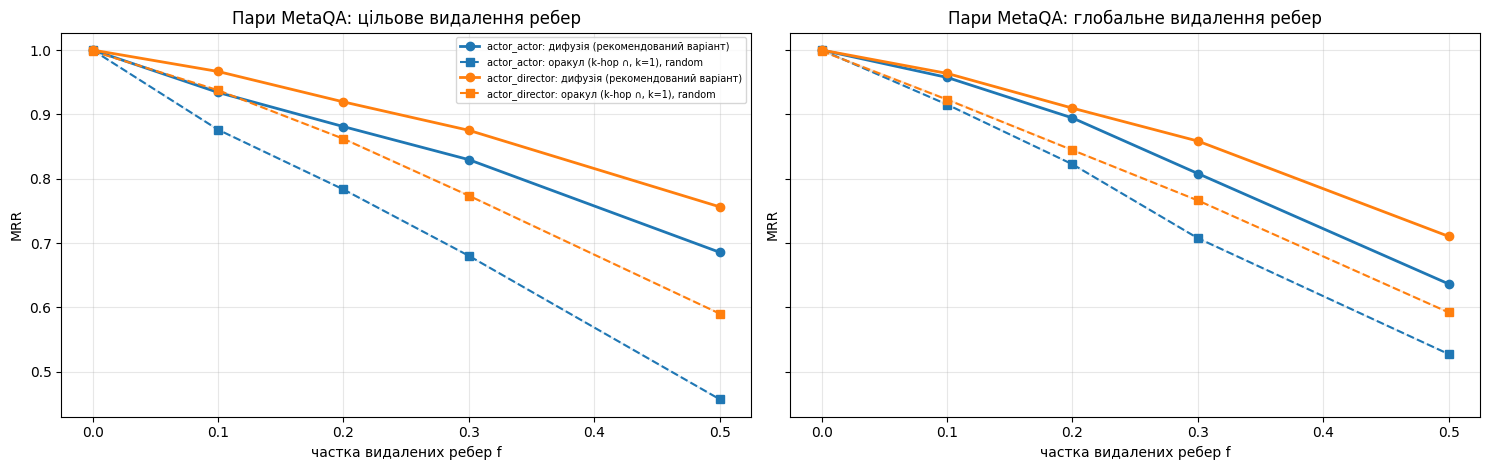

In [2]:
rng = np.random.default_rng(0)
PAIRS = pd.concat([grp.iloc[np.sort(rng.choice(len(grp), min(300, len(grp)), replace=False))]
                   for _, grp in P0.groupby("kind", sort=True)]).reset_index(drop=True)
if SMALL: PAIRS = PAIRS.groupby("kind").head(10).reset_index(drop=True)
FS = [0.0, 0.1, 0.2, 0.3, 0.5]
REL_OF = {"actor_actor": ("starred_actors", "starred_actors"), "actor_director": ("starred_actors", "directed_by")}

def eval_pair(gn, s1, s2, ans):
    diff = combine_scores([rank(gn, s1, "heat", t=1.0, normalize="sqrt_degree"),
                           rank(gn, s2, "heat", t=1.0, normalize="sqrt_degree")], "product")
    orc = rank(gn, [s1, s2], "k_hop", hops=1, agg="max")
    order_d = M.ranking(diff, seeds=[s1, s2], ties="random", seed=0)
    pos = {v: i + 1 for i, v in enumerate(order_d)}
    out = dict(MRR_дифузії=M.reciprocal_rank(diff, ans, seeds=[s1, s2]))
    for t in TIES:
        out[f"MRR_оракула_{t}"] = M.reciprocal_rank(orc, ans, seeds=[s1, s2], ties=t)
    return out, pos

rows, lost_rows, iso = [], [], []
t0 = time.perf_counter()
for mode in ("цільове", "глобальне"):
    for f in FS:
        for ns in (NOISE_SEEDS if f > 0 else [0]):
            r = np.random.default_rng(300 + ns)
            if mode == "глобальне" and f > 0:
                gglob = graph_from_triples(MQ.perturb_triples(trip0, f, 0.0, seed=300 + ns)[0], g0)
            n_iso = 0
            for p in PAIRS.itertuples():
                ans = set(p.answers)
                if mode == "цільове" and f > 0:
                    tr = list(trip0); removed = set()
                    for movie in sorted(ans):        # детермінований порядок (не залежить від солі хешування)
                        for seed_node, rel in zip((p.seed_1, p.seed_2), REL_OF[p.kind]):
                            if r.random() < f: removed.add((movie, rel, seed_node))
                    gn = graph_from_triples([t for t in tr if t not in removed], g0) if removed else g0
                else:
                    gn = gglob if (mode == "глобальне" and f > 0) else g0
                if gn.degree(p.seed_1) == 0 or gn.degree(p.seed_2) == 0:
                    n_iso += 1
                    rows.append(dict(режим=mode, f=f, seed=ns, kind=p.kind, ізольована=True, MRR_дифузії=0.0,
                                     **{f"MRR_оракула_{t}": 0.0 for t in TIES}))
                    continue
                ev, pos = eval_pair(gn, p.seed_1, p.seed_2, ans)
                rows.append(dict(режим=mode, f=f, seed=ns, kind=p.kind, ізольована=False, **ev))
                # відповіді, які оракул втратив (не суміжні з обома запитами на зашумленому графі)
                for a in ans:
                    if not (gn.has_edge(p.seed_1, a) and gn.has_edge(p.seed_2, a)):
                        rk = pos.get(a, np.inf)
                        lost_rows.append(dict(режим=mode, f=f, kind=p.kind, топ1=rk <= 1, топ5=rk <= 5, топ10=rk <= 10))
            iso.append(dict(режим=mode, f=f, seed=ns, ізольованих_пар=n_iso))
print(f"Пари: {time.perf_counter() - t0:.0f} с")
pairs_res = pd.DataFrame(rows)
pairs_res.to_csv(RES / "07_pary_po_parakh.csv", index=False)
mcols = ["MRR_дифузії"] + [f"MRR_оракула_{t}" for t in TIES]
# варіант 1: ізольовані пари виключено; варіант 2: ізольовані пари враховано як MRR = 0 для обох методів
pr = pairs_res[~pairs_res["ізольована"]].groupby(["режим", "f", "kind"])[mcols].mean().reset_index()
pr0 = pairs_res.groupby(["режим", "f", "kind"])[mcols].mean().reset_index()
iso_k = pairs_res.groupby(["режим", "f", "kind"])["ізольована"].agg(ізольованих="sum", усього="size").reset_index()
pr = pr.merge(iso_k, on=["режим", "f", "kind"])
pr.to_csv(RES / "07_pary_vydalennya.csv", index=False)
pr0.to_csv(RES / "07_pary_vydalennya_z_nulyamy.csv", index=False)
print("Пари з ізольованим вузлом запиту (виключено):", pd.DataFrame(iso).groupby(["режим", "f"])["ізольованих_пар"].sum().to_dict())
print("Варіант 1 — ізольовані пари виключено:"); display(pr)
print("Варіант 2 — ізольовані пари враховано як MRR = 0 для обох методів:"); display(pr0)
lost = pd.DataFrame(lost_rows)
if len(lost):
    lt = lost.groupby(["режим", "f"]).agg(втрачених_відповідей=("топ1", "size"), у_топ1=("топ1", "mean"),
                                         у_топ5=("топ5", "mean"), у_топ10=("топ10", "mean")).reset_index()
    lt.to_csv(RES / "07_pary_vtracheni_vidpovidi.csv", index=False)
    print("Відповіді, втрачені оракулом: яку частку дифузія все ж ставить у топ-k"); display(lt)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, mode in zip(axs, ("цільове", "глобальне")):
    for i, kind in enumerate(("actor_actor", "actor_director")):
        s0 = pr[(pr["режим"] == mode) & (pr["kind"] == kind)].set_index("f").reindex(FS)
        ax.plot(FS, s0["MRR_дифузії"], "o-", color=f"C{i}", lw=2, label=f"{kind}: дифузія (рекомендований варіант)")
        ax.plot(FS, s0["MRR_оракула_random"], "s--", color=f"C{i}", label=f"{kind}: оракул (k-hop ∩, k=1), random")
        ax.fill_between(FS, s0["MRR_оракула_pessimistic"], s0["MRR_оракула_optimistic"], color=f"C{i}", alpha=0.12)
    ax.set_title(f"Пари MetaQA: {mode} видалення ребер"); ax.set_xlabel("частка видалених ребер f")
    ax.set_ylabel("MRR"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "07_pary_vydalennya.png", dpi=200); plt.show()

## Завдання 7.3. Чутливість до вибору вузлів запиту

**(а) Заміна вузла запиту на випадкового сусіда.** Міряємо перетин топ-10 і τ_b на топ-50 між ранжуваннями з q і з q′ (обидва вузли виключено), для дифузії і для найкоротшого шляху (random-нічиї). На SBM окремо — сусід зі своєї і з чужої спільноти. На MetaQA — запити-фільми і запити-люди.

**(б) Розкид якості між запитами одного типу.** На MetaQA за чистим графом з 7.1: міжквартильний розмах nDCG@10 і частка питань з nDCG@10 = 0 у межах qtype, усереднені за hop.

,граф,тип,метод,перетин_топ10,τ_b_топ50,запитів
0,MetaQA,запит-не фільм,"дифузія (PPR, α=0.5, сирі)",0.903,0.841,101
1,MetaQA,запит-не фільм,найкор. шлях,0.846,0.842,101
2,MetaQA,запит-фільм,"дифузія (PPR, α=0.5, сирі)",0.477,0.356,99
3,MetaQA,запит-фільм,найкор. шлях,0.432,0.432,99
4,SBM,сусід з чужої спільноти,"дифузія (теплове ядро, t=7, π/√d)",0.008,-0.363,13
5,SBM,сусід з чужої спільноти,найкор. шлях,0.008,0.005,13
6,SBM,сусід зі своєї спільноти,"дифузія (теплове ядро, t=7, π/√d)",0.097,-0.112,37
7,SBM,сусід зі своєї спільноти,найкор. шлях,0.051,-0.011,37


IQR             середнє             частка_нулів            
hop                            1     2     3       1     2     3            1     2     3
метод                                                                                    
k-hop, k=2                 0.161 0.238 0.112   0.684 0.288 0.096        0.023 0.278 0.639
дифузія (PPR, α=0.5, сирі) 0.176 0.256 0.134   0.744 0.337 0.158        0.005 0.188 0.578
найкор. шлях               0.148 0.232 0.123   0.736 0.276 0.097        0.014 0.290 0.622

/tmp/ipykernel_121779/1366787987.py:68: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(data, labels=labels); axs[1].set_ylabel("nDCG@10 окремих питань")


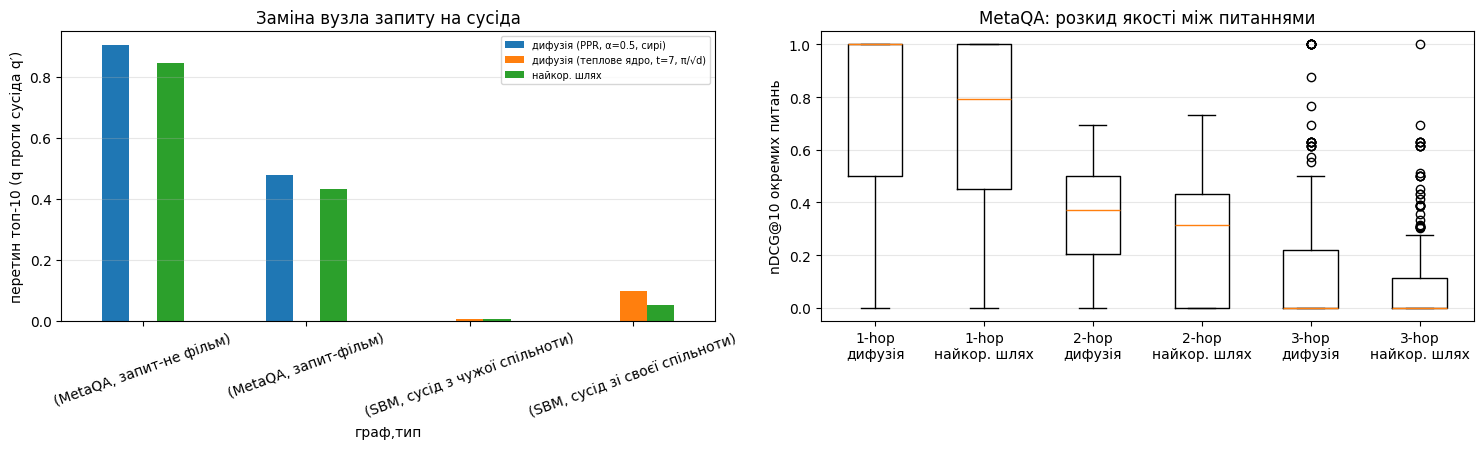

In [6]:
RESOLVE = 1e-10
def prep(s, excl):
    x = s.drop(index=[v for v in excl if v in s.index]).astype(float)
    m = np.nanmax(np.abs(x.to_numpy())) if len(x) else 0
    x = x / m if m > 0 else x
    x[x < RESOLVE] = 0.0
    return x.fillna(0.0).round(12)

def top_set(x, k):
    x = x[x > 0]
    if len(x) <= k: return set(x.index)
    thr = np.sort(x.to_numpy())[::-1][k - 1]
    return set(x[x >= thr].index)

def tie_break_random(s, seed=0):
    # для базових методів: випадкове розбиття нічиїх через крихітний шум у межах групи
    r = np.random.default_rng(seed)
    return s + r.random(len(s)) * 1e-9 * s.abs().max()

def compare(s1, s2, excl):
    a, b = prep(s1, excl), prep(s2, excl)
    A, B = top_set(a, 10), top_set(b, 10)
    U = sorted((top_set(a, 50) | top_set(b, 50)) & set(a[a > 0].index) & set(b[b > 0].index))
    t = kendalltau(a[U], b[U]).statistic if len(U) >= 3 else np.nan
    return len(A & B) / min(len(A), len(B)) if A and B else np.nan, t

rows = []
r = np.random.default_rng(11)
for q in SBM_Q:
    nb = sorted(g_sbm.neighbors(q)); q2 = nb[int(r.integers(len(nb)))]
    same = g_sbm.nodes[q]["community"] == g_sbm.nodes[q2]["community"]
    for name, f in (("дифузія (теплове ядро, t=7, π/√d)", lambda x: rank(g_sbm, x, "heat", t=7.0, normalize="sqrt_degree")),
                    ("найкор. шлях", lambda x: tie_break_random(rank(g_sbm, x, "shortest_path").fillna(0)))):
        o, t = compare(f(q), f(q2), [q, q2])
        rows.append(dict(граф="SBM", тип=("сусід зі своєї спільноти" if same else "сусід з чужої спільноти"), метод=name,
                         перетин_топ10=o, τ_b_топ50=t))
topics = QS.drop_duplicates("topic")
topics = topics.iloc[np.sort(np.random.default_rng(12).choice(len(topics), min(30 if SMALL else 200, len(topics)), replace=False))]
for q in topics.topic:
    nb = sorted(g0.neighbors(q)); q2 = nb[int(r.integers(len(nb)))]
    typ = "запит-фільм" if "movie" in g0.nodes[q]["kinds"] else "запит-не фільм"
    for name, f in (("дифузія (PPR, α=0.5, сирі)", lambda x: rank(g0, x, "ppr", alpha=0.5)),
                    ("найкор. шлях", lambda x: tie_break_random(rank(g0, x, "shortest_path").fillna(0)))):
        o, t = compare(f(q), f(q2), [q, q2])
        rows.append(dict(граф="MetaQA", тип=typ, метод=name, перетин_топ10=o, τ_b_топ50=t))
sens = pd.DataFrame(rows).groupby(["граф", "тип", "метод"]).agg(перетин_топ10=("перетин_топ10", "mean"),
                                                              τ_b_топ50=("τ_b_топ50", "mean"), запитів=("перетин_топ10", "size")).reset_index()
sens.to_csv(RES / "07_chutlyvist_zapytu.csv", index=False)
display(sens)

clean = mq_noise[(mq_noise["рівень"] == "чистий") & (mq_noise["нічиї"] == "random") &
                 mq_noise["метод"].isin(["дифузія (PPR, α=0.5, сирі)", "найкор. шлях", "k-hop, k=2"])]
spread = clean.groupby(["метод", "hop", "qtype"])["nDCG10"].agg(
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25), частка_нулів=lambda x: (x == 0).mean(), середнє="mean"
).groupby(["метод", "hop"]).mean().reset_index()
spread.to_csv(RES / "07_rozkyd_metryk.csv", index=False)
display(spread.pivot_table(index="метод", columns="hop", values=["середнє", "IQR", "частка_нулів"]))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
s0 = sens.pivot_table(index=["граф", "тип"], columns="метод", values="перетин_топ10")
s0.plot.bar(ax=axs[0], rot=20); axs[0].set_ylabel("перетин топ-10 (q проти сусіда q′)")
axs[0].set_title("Заміна вузла запиту на сусіда"); axs[0].grid(alpha=0.3, axis="y"); axs[0].legend(fontsize=7)
data, labels = [], []
for h in (1, 2, 3):
    for m in ("дифузія (PPR, α=0.5, сирі)", "найкор. шлях"):
        data.append(clean[(clean["метод"] == m) & (clean["hop"] == h)]["nDCG10"].to_numpy())
        labels.append(f"{h}-hop\n{'дифузія' if m.startswith('дифузія') else 'найкор. шлях'}")
axs[1].boxplot(data, labels=labels); axs[1].set_ylabel("nDCG@10 окремих питань")
axs[1].set_title("MetaQA: розкид якості між питаннями"); axs[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(FIG / "07_chutlyvist_zapytu.png", dpi=200); plt.show()

### SBM: якість при заміні вузла запиту на сусіда

Низький перетин топ-10 ще не означає нестійкості: обидва списки можуть складатися з правильної спільноти. Тому для тих самих запитів q і тих самих сусідів q′ (той самий генератор з тим самим seed) рахуємо P@10 ранжування з q′ щодо двох наборів правильних відповідей:
- **спільноти q** — вихідний намір запиту;
- **власної спільноти q′**.

Для порівняння наводимо P@10 ранжування з самого q.

In [2]:
_g = G.sbm([200] * 5, 0.05, 0.005, seed=6)
_comm = G.communities(_g)
_r = np.random.default_rng(2); _nodes = list(_g.nodes())
_Q = [_nodes[i] for i in _r.choice(len(_nodes), 10 if SMALL else 50, replace=False)]
_rn = np.random.default_rng(11)          # той самий генератор і порядок вибору сусідів, що в 7.3
_rows = []
for q in _Q:
    nb = sorted(_g.neighbors(q)); q2 = nb[int(_rn.integers(len(nb)))]
    cq, cq2 = _g.nodes[q]["community"], _g.nodes[q2]["community"]
    typ = "сусід зі своєї спільноти" if cq == cq2 else "сусід з чужої спільноти"
    for name, f in (("дифузія (теплове ядро, t=7, π/√d)", lambda x: rank(_g, x, "heat", t=7.0, normalize="sqrt_degree")),
                    ("найкор. шлях", lambda x: rank(_g, x, "shortest_path"))):
        s_q, s_q2 = f(q), f(q2)
        excl = [q, q2]
        _rows.append(dict(тип=typ, метод=name,
                          P10_з_q=M.precision_at_k(s_q, _comm[cq] - set(excl), 10, seeds=excl),
                          P10_з_q2_щодо_спільноти_q=M.precision_at_k(s_q2, _comm[cq] - set(excl), 10, seeds=excl),
                          P10_з_q2_щодо_спільноти_q2=M.precision_at_k(s_q2, _comm[cq2] - set(excl), 10, seeds=excl)))
q_sens = pd.DataFrame(_rows).groupby(["тип", "метод"]).agg(
    запитів=("P10_з_q", "size"), P10_з_q=("P10_з_q", "mean"),
    P10_з_q2_щодо_спільноти_q=("P10_з_q2_щодо_спільноти_q", "mean"),
    P10_з_q2_щодо_спільноти_q2=("P10_з_q2_щодо_спільноти_q2", "mean")).reset_index()
q_sens.to_csv(RES / "07_chutlyvist_zapytu_yakist_sbm.csv", index=False)
display(q_sens)

,тип,метод,запитів,P10_з_q,P10_з_q2_щодо_спільноти_q,P10_з_q2_щодо_спільноти_q2
0,сусід з чужої спільноти,"дифузія (теплове ядро, t=7, π/√d)",13,0.931,0.023,0.908
1,сусід з чужої спільноти,найкор. шлях,13,0.723,0.108,0.685
2,сусід зі своєї спільноти,"дифузія (теплове ядро, t=7, π/√d)",37,0.873,0.900,0.900
3,сусід зі своєї спільноти,найкор. шлях,37,0.765,0.730,0.730


## Завдання 7.4. Три способи розрахунку: точність і час

**Порівняння способів між собою** — на **вже побудованій** матриці P, тобто прямими викликами функцій `reldiff.models`, щоб час побудови P не змазував різницю:
- PPR (α = 0.15): ітерація (tol = 10⁻¹⁰), розріджена лінійна система, щільна обернена матриця;
- теплове ядро (t = 5.67): обрізаний ряд, `expm_multiply`, щільна `expm`.

**Практичний час** — повний виклик `rank()` разом з частиною, що йде на побудову W і P.

Графи ER і BA (середній степінь ≈ 10) при n ∈ {250, 500, 1000, 2000, 3000}, точка n = 16000 для ілюстрації масштабування (без щільного еталону) і MetaQA (n = 2957). Час — медіана з 5 повторень. Точність — ‖x − x_щільний‖₁; при n = 16000 — розбіжність між двома розрідженими способами.

In [7]:
def timeit(f, rep=5):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); out = f(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out

NS = [250, 500, 1000] if SMALL else [250, 500, 1000, 2000, 3000, 16000]
graphs_t = []
for n in NS:
    graphs_t.append((f"ER n={n}", n, G.erdos_renyi(n, 10 / (n - 1), seed=n)))
    graphs_t.append((f"BA n={n}", n, G.barabasi_albert(n, 5, seed=n)))
graphs_t.append(("MetaQA", g0.number_of_nodes(), g0))
rows = []
for name, n, g in graphs_t:
    W, nodes = models.weight_matrix(g)
    s = models.seed_vector(len(nodes), [0])
    t_build, P = timeit(lambda: models.transition_matrix(models.weight_matrix(g)[0], s=s))
    dense_ok = len(nodes) <= models.MAX_DENSE_N
    rep = 3 if len(nodes) > 5000 else 5
    tp = {}
    tp["ітерація"] = timeit(lambda: models.ppr_iterative(P, s, 0.15, tol=1e-10)[0], rep)
    tp["лінійна система"] = timeit(lambda: models.ppr_linear(P, s, 0.15), rep)
    if dense_ok: tp["щільна обернена"] = timeit(lambda: models.ppr_dense_inverse(P, s, 0.15), rep)
    th = {}
    th["обрізаний ряд"] = timeit(lambda: models.heat_series(P, s, 5.67)[0], rep)
    th["expm_multiply"] = timeit(lambda: models.heat_expm_multiply(P, s, 5.67), rep)
    if dense_ok: th["щільна expm"] = timeit(lambda: models.heat_dense_expm(P, s, 5.67), rep)
    for model, d, ref_name, alt in (("PPR", tp, "щільна обернена", ("ітерація", "лінійна система")),
                                    ("теплове ядро", th, "щільна expm", ("обрізаний ряд", "expm_multiply"))):
        for meth, (tm, x) in d.items():
            if dense_ok:
                err = np.abs(x - d[ref_name][1]).sum()
            else:
                other = alt[1] if meth == alt[0] else alt[0]
                err = np.abs(x - d[other][1]).sum()
            rows.append(dict(граф=name, n=len(nodes), модель=model, спосіб=meth, час_с=tm,
                             похибка_L1=err, еталон=("щільний" if dense_ok else f"проти «{other}»")))
    t_rank_ppr, _ = timeit(lambda: rank(g, nodes[0], "ppr", alpha=0.15), rep)
    t_rank_heat, _ = timeit(lambda: rank(g, nodes[0], "heat", t=5.67), rep)
    rows.append(dict(граф=name, n=len(nodes), модель="PPR", спосіб="rank() повністю", час_с=t_rank_ppr,
                     частка_побудови_P=t_build / t_rank_ppr))
    rows.append(dict(граф=name, n=len(nodes), модель="теплове ядро", спосіб="rank() повністю", час_с=t_rank_heat,
                     частка_побудови_P=t_build / t_rank_heat))
    print(f"{name}: готово")
timing = pd.DataFrame(rows)
timing.to_csv(RES / "07_chas_tochnist.csv", index=False)
pd.set_option("display.float_format", "{:.3g}".format)
display(timing.pivot_table(index=["модель", "спосіб"], columns="граф", values="час_с", sort=False))
display(timing.pivot_table(index=["модель", "спосіб"], columns="граф", values="похибка_L1", sort=False))
display(timing[timing["спосіб"] == "rank() повністю"][["граф", "модель", "час_с", "частка_побудови_P"]])

ER n=250: готово


BA n=250: готово


ER n=500: готово


BA n=500: готово


ER n=1000: готово


BA n=1000: готово


... (6 outputs left out)

MetaQA: готово


граф                          ER n=250  BA n=250  ER n=500  BA n=500  ER n=1000  BA n=1000  ER n=2000  BA n=2000  ER n=3000  BA n=3000  ER n=16000  BA n=16000  MetaQA
модель       спосіб                                                                                                                                                   
PPR          ітерація         0.000548  0.000556   0.00059  0.000647   0.000866   0.000893    0.00133    0.00116    0.00186    0.00183      0.0113      0.0091 0.00388
             лінійна система   0.00222   0.00219    0.0106   0.00853     0.0608     0.0588      0.442      0.445       1.47       1.45         359         298  0.0196
             щільна обернена    0.0031   0.00327      0.01   0.00874     0.0821     0.0745      0.364      0.365      0.908      0.965         NaN         NaN    0.78
             rank() повністю    0.0161    0.0104    0.0166    0.0125     0.0673     0.0688      0.517      0.458       1.57       1.48         338         301  0.0286
теплове ядро обрізаний ряд    0.000662  0.000766  0.000611  0.000833    0.00126    0.00105    0.00147    0.00151    0.00216    0.00295     0.00824     0.00761 0.00106
             expm_multiply     0.00232   0.00326   0.00226   0.00239    0.00309    0.00252    0.00386    0.00602    0.00465    0.00631      0.0145      0.0156  0.0031
             щільна expm         0.121     0.112     0.155     0.156      0.351      0.356       1.46       1.56       5.07       5.11         NaN         NaN    3.99
             rank() повністю   0.00399   0.00452   0.00571   0.00547    0.00915    0.00895     0.0168      0.016     0.0244     0.0231       0.126       0.123  0.0111

граф                          ER n=250  BA n=250  ER n=500  BA n=500  ER n=1000  BA n=1000  ER n=2000  BA n=2000  ER n=3000  BA n=3000  ER n=16000  BA n=16000   MetaQA
модель       спосіб                                                                                                                                                    
PPR          ітерація         5.67e-12   6.9e-12  5.75e-12  3.04e-12   4.24e-12   4.87e-12   5.19e-12   4.61e-12   6.37e-12   4.64e-12     7.1e-12    4.58e-12 7.71e-12
             лінійна система  6.07e-16  2.68e-16  4.56e-16  5.61e-16   5.88e-16   4.69e-16   1.16e-15   7.78e-16   1.18e-15   1.51e-15     7.1e-12    4.58e-12 5.07e-16
             щільна обернена         0         0         0         0          0          0          0          0          0          0         NaN         NaN        0
теплове ядро обрізаний ряд    8.91e-16  6.54e-16  5.02e-16  6.02e-16   6.69e-16    5.8e-16   8.25e-16   8.22e-16   6.98e-16   6.26e-16    4.25e-16     5.5e-16 1.33e-15
             expm_multiply    6.89e-16  6.11e-16  5.23e-16  6.22e-16   6.24e-16   5.28e-16   6.72e-16   6.15e-16   7.48e-16   6.73e-16    4.25e-16     5.5e-16 1.15e-15
             щільна expm             0         0         0         0          0          0          0          0          0          0         NaN         NaN        0

,граф,модель,час_с,частка_побудови_P
6,ER n=250,PPR,0.0161,0.125
7,ER n=250,теплове ядро,0.00399,0.506
14,BA n=250,PPR,0.0104,0.178
15,BA n=250,теплове ядро,0.00452,0.411
22,ER n=500,PPR,0.0166,0.224
23,ER n=500,теплове ядро,0.00571,0.652
30,BA n=500,PPR,0.0125,0.266
31,BA n=500,теплове ядро,0.00547,0.606
38,ER n=1000,PPR,0.0673,0.0938
39,ER n=1000,теплове ядро,0.00915,0.691


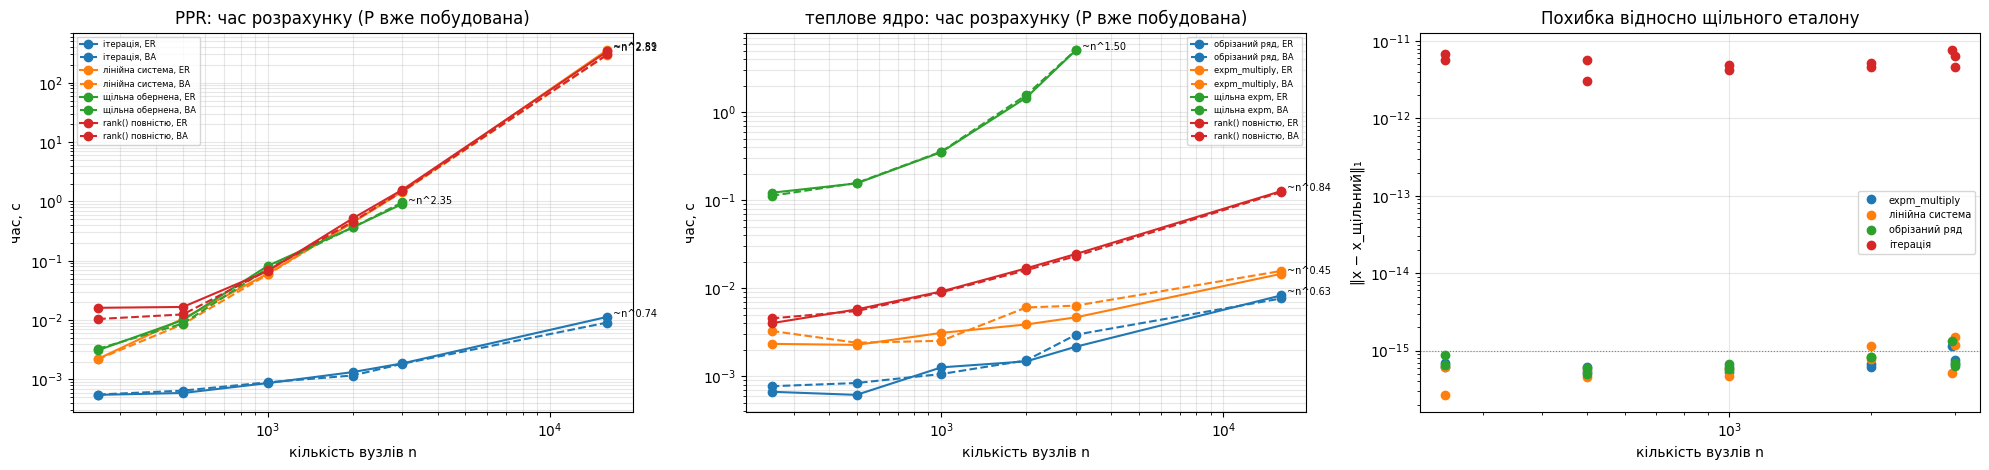

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, model in zip(axs[:2], ("PPR", "теплове ядро")):
    for i, meth in enumerate([m for m in timing[timing["модель"] == model]["спосіб"].unique()]):
        for fam, ls in (("ER", "-"), ("BA", "--")):
            sub = timing[(timing["модель"] == model) & (timing["спосіб"] == meth) & timing["граф"].str.startswith(fam)].sort_values("n")
            if len(sub) < 2: continue
            ax.loglog(sub["n"], sub["час_с"], ls, marker="o", color=f"C{i}", label=f"{meth}, {fam}")
            if fam == "ER" and len(sub) >= 3:
                k = np.polyfit(np.log(sub["n"]), np.log(sub["час_с"]), 1)[0]
                ax.annotate(f"~n^{k:.2f}", (sub["n"].iloc[-1], sub["час_с"].iloc[-1]), fontsize=7, xytext=(4, 0), textcoords="offset points")
    ax.set_title(f"{model}: час розрахунку (P вже побудована)"); ax.set_xlabel("кількість вузлів n"); ax.set_ylabel("час, с")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=6)
sub = timing[timing["похибка_L1"].notna() & (timing["еталон"] == "щільний") & ~timing["спосіб"].isin(["щільна обернена", "щільна expm"])]
for i, (meth, d) in enumerate(sub.groupby("спосіб")):
    axs[2].semilogy(d["n"], np.maximum(d["похибка_L1"], 1e-17), "o", color=f"C{i}", label=meth)
axs[2].axhline(1e-15, color="gray", ls=":", lw=0.8); axs[2].set_xscale("log")
axs[2].set_title("Похибка відносно щільного еталону"); axs[2].set_xlabel("кількість вузлів n"); axs[2].set_ylabel("‖x − x_щільний‖₁")
axs[2].grid(alpha=0.3); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "07_chas_tochnist.png", dpi=200); plt.show()

## Завдання 7.5. Стійкість висновків п. 5 і п. 6

Повторюємо ключові таблиці на:
- **іншому підграфі MetaQA** (500 фільмів, seed = 1);
- **підмножині повних питань і пар** (`complete_wrt_full_kb`) основного підграфа.

**Для п. 5** — MRR трьох найкращих за найгіршим випадком варіантів і оракула на парах (до 300 кожного типу). **Для п. 6** — макро-nDCG@10 обраного варіанта і базових методів за hop і бюджет k-hop (до 50 питань на qtype з test).

In [9]:
if not (Path("../data/metaqa/processed/movies500_seed1") / "questions.csv").exists():
    MQ.prepare("../data/metaqa", n_movies=500, seed=1)
g1, Q1, P1 = MQ.load_processed("../data/metaqa", 500, 1)
print(f"Підграф seed = 1: {g1.number_of_nodes()} вузлів, {g1.number_of_edges()} ребер; питань {len(Q1)}, пар {len(P1)}")
TOP3 = [("теплове ядро, t=1", dict(method="heat", t=1.0), "sqrt_degree", "product"),
        ("теплове ядро, t=5.67", dict(method="heat", t=0.85 / 0.15), "sqrt_degree", "product"),
        ("PPR, α=0.05", dict(method="ppr", alpha=0.05), "degree", "min")]

def p5_table(g, pairs, label, n_per=300):
    r = np.random.default_rng(0)
    smp = pd.concat([grp.iloc[np.sort(r.choice(len(grp), min(n_per if not SMALL else 10, len(grp)), replace=False))]
                     for _, grp in pairs.groupby("kind", sort=True)])
    rows, cache = [], {}
    for p in smp.itertuples():
        seeds, ans = [p.seed_1, p.seed_2], set(p.answers)
        for name, kw, norm, comb in TOP3:
            parts = []
            for q in seeds:
                key = (q, name, norm)
                if key not in cache: cache[key] = rank(g, q, normalize=norm, **kw)
                parts.append(cache[key])
            rows.append(dict(дані=label, kind=p.kind, метод=f"{name}, {norm}, {comb}",
                             MRR=M.reciprocal_rank(combine_scores(parts, comb), ans, seeds=seeds)))
        orc = rank(g, seeds, "k_hop", hops=1, agg="max")
        rows.append(dict(дані=label, kind=p.kind, метод="оракул (k-hop ∩, k=1), random",
                         MRR=M.reciprocal_rank(orc, ans, seeds=seeds)))
    return pd.DataFrame(rows).groupby(["дані", "kind", "метод"])["MRR"].agg(["mean", "size"]).reset_index()

def p6_tables(g, Qsub, label, n_per=50):
    smp = strat(Qsub[~Qsub["qtype"].isin(RARE)], n_per if not SMALL else 3, seed=8)
    a, b, _ = run_mq(g, smp, label, 0)
    a, b = pd.DataFrame(a), pd.DataFrame(b)
    q = macro(a[a["нічиї"] == "random"], ["рівень", "метод", "hop"], "nDCG10").reset_index().rename(columns={"рівень": "дані"})
    bb = b.groupby(["рівень", "hop", "k"]).agg(N_медіана=("N", "median"), повнота_khop=("повнота_khop", "mean"),
                                              повнота_дифузії=("повнота_дифузії", "mean"),
                                              khop_0_дифузія_знаходить=("khop_0_дифузія_знаходить", "mean"),
                                              питань=("N", "size")).reset_index().rename(columns={"рівень": "дані"})
    return q, bb

t0 = time.perf_counter()
p5 = pd.concat([p5_table(g1, P1, "підграф seed=1"),
                p5_table(g0, P0[P0["complete_wrt_full_kb"]], "seed=0, лише повні пари")])
Qt0 = Q0[(Q0["split"] == "test") & Q0["complete_wrt_full_kb"]]
Qt1 = Q1[Q1["split"] == "test"]
q6a, b6a = p6_tables(g1, Qt1, "підграф seed=1")
q6b, b6b = p6_tables(g0, Qt0, "seed=0, лише повні питання")
print(f"Стійкість: {time.perf_counter() - t0:.0f} с")
p5.to_csv(RES / "07_stiikist_p5.csv", index=False)
q6 = pd.concat([q6a, q6b]); b6 = pd.concat([b6a, b6b])
q6.to_csv(RES / "07_stiikist_p6_yakist.csv", index=False); b6.to_csv(RES / "07_stiikist_p6_byudzhet.csv", index=False)
display(p5.pivot_table(index="метод", columns=["дані", "kind"], values="mean"))
display(q6.pivot_table(index="метод", columns=["дані", "hop"], values="nDCG10"))
display(b6[b6["hop"] == 3])

Підграф seed = 1: 2788 вузлів, 4989 ребер; питань 16986, пар 3584


Стійкість: 231 с


дані                                       seed=0, лише повні пари                підграф seed=1               
kind                                                   actor_actor actor_director    actor_actor actor_director
метод                                                                                                          
PPR, α=0.05, degree, min                                     0.924          0.935          0.909          0.913
оракул (k-hop ∩, k=1), random                                    1          0.998              1              1
теплове ядро, t=1, sqrt_degree, product                          1              1              1              1
теплове ядро, t=5.67, sqrt_degree, product                   0.994          0.997              1          0.993

дані                       seed=0, лише повні питання                підграф seed=1             
hop                                                 1     2        3              1     2      3
метод                                                                                           
k-hop, k=2                                      0.678 0.293   0.0979          0.696 0.283 0.0561
дифузія (PPR, α=0.5, сирі)                      0.728 0.339    0.152          0.729 0.325  0.104
найкор. шлях                                    0.711 0.279    0.101          0.686 0.261 0.0753
схожість Σ|N(v)∩N(q)|                               0 0.434 0.000868              0 0.421      0

,дані,hop,k,N_медіана,повнота_khop,повнота_дифузії,khop_0_дифузія_знаходить,питань
6,підграф seed=1,3,1,9,0.0997,0.0997,0,431
7,підграф seed=1,3,2,104,0.0997,0.345,0.343,431
8,підграф seed=1,3,3,697,1,0.981,0,431
6,"seed=0, лише повні питання",3,1,7,0.146,0.146,0,148
7,"seed=0, лише повні питання",3,2,108,0.15,0.442,0.284,148
8,"seed=0, лише повні питання",3,3,776,1,0.993,0,148


In [10]:
# Підсумкова таблиця: ключові числа на трьох варіантах даних (основні — з результатів п. 5 і п. 6)
PREV = Path("../results")   # результати п. 5 і п. 6 завжди беремо з основної папки
p5_main = pd.read_csv(PREV / "05_metaqa_pary.csv")
p6_bud = pd.read_csv(PREV / "06_metaqa_byudzhet_khop.csv")
p6_main = pd.read_csv(PREV / "06_metaqa_obranyi_vs_bazovi.csv")
def get(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items(): m &= (df[k] == v).to_numpy()
    return df[m]
rows = []
for kind in ("actor_actor", "actor_director"):
    rows.append(dict(показник=f"п. 5, MRR рекомендованого варіанта, {kind}",
                     основний=get(p5_main, kind=kind, метод="теплове ядро, t=1", нормування="π/√d", поєднання="product")["MRR"].item(),
                     **{lbl: get(p5, дані=lbl, kind=kind, метод="теплове ядро, t=1, sqrt_degree, product")["mean"].item()
                        for lbl in ("підграф seed=1", "seed=0, лише повні пари")}))
    rows.append(dict(показник=f"п. 5, MRR оракула (random), {kind}",
                     основний=get(p5_main, kind=kind, метод="спільні сусіди запитів (оракул)", нічиї="random")["MRR"].item(),
                     **{lbl: get(p5, дані=lbl, kind=kind, метод="оракул (k-hop ∩, k=1), random")["mean"].item()
                        for lbl in ("підграф seed=1", "seed=0, лише повні пари")}))
for h in (1, 2, 3):
    rows.append(dict(показник=f"п. 6, макро-nDCG@10 дифузії, {h}-hop",
                     основний=get(p6_main, варіант="ОБРАНИЙ: PPR, α=0.5, сирі", hop=str(h))["nDCG@10"].item(),
                     **{lbl: get(q6, дані=lbl, метод="дифузія (PPR, α=0.5, сирі)", hop=h)["nDCG10"].item()
                        for lbl in ("підграф seed=1", "seed=0, лише повні питання")}))
    rows.append(dict(показник=f"п. 6, макро-nDCG@10 найкор. шляху (random), {h}-hop",
                     основний=get(p6_main, варіант="найкор. шлях [random]", hop=str(h))["nDCG@10"].item(),
                     **{lbl: get(q6, дані=lbl, метод="найкор. шлях", hop=h)["nDCG10"].item()
                        for lbl in ("підграф seed=1", "seed=0, лише повні питання")}))
for col, nm in (("повнота_khop", "k-hop"), ("повнота_дифузії", "дифузія")):
    rows.append(dict(показник=f"п. 6, 3-hop, бюджет k=2: повнота {nm}",
                     основний=get(p6_bud, hop=3, k=2)[col].item(),
                     **{lbl: get(b6, дані=lbl, hop=3, k=2)[col].item() for lbl in ("підграф seed=1", "seed=0, лише повні питання")}))
summ = pd.DataFrame(rows)
summ.to_csv(RES / "07_stiikist_vysnovkiv.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format)
display(summ)

,показник,основний,підграф seed=1,"seed=0, лише повні пари","seed=0, лише повні питання"
0,"п. 5, MRR рекомендованого варіанта, actor_actor",1.000,1.000,1.000,NaN
1,"п. 5, MRR оракула (random), actor_actor",1.000,1.000,1.000,NaN
2,"п. 5, MRR рекомендованого варіанта, actor_dire...",1.000,1.000,1.000,NaN
3,"п. 5, MRR оракула (random), actor_director",0.998,1.000,0.998,NaN
4,"п. 6, макро-nDCG@10 дифузії, 1-hop",0.738,0.729,NaN,0.728
5,"п. 6, макро-nDCG@10 найкор. шляху (random), 1-hop",0.728,0.686,NaN,0.711
6,"п. 6, макро-nDCG@10 дифузії, 2-hop",0.340,0.325,NaN,0.339
7,"п. 6, макро-nDCG@10 найкор. шляху (random), 2-hop",0.280,0.261,NaN,0.279
8,"п. 6, макро-nDCG@10 дифузії, 3-hop",0.158,0.104,NaN,0.152
9,"п. 6, макро-nDCG@10 найкор. шляху (random), 3-hop",0.097,0.075,NaN,0.101


## Висновки

Параметри не перепідбирали під шум. Головне порівняння всюди — з random-розбиттям нічиїх базових методів.

1. **Шум у ребрах.**
   - **SBM (p_out = 0.005).** Дифузія лишається найкращою на всіх рівнях шуму: P@10 становить 0.896 на чистому графі, 0.805 при видаленні 30% ребер і 0.825 при додаванні 30% хибних. Найкоротший шлях дає 0.760, 0.730 і 0.632, Σ-схожість — 0.856, 0.713 і 0.717. До видалення найкоротший шлях чутливий менше (−0.03 проти −0.09 у дифузії), до хибних ребер — більше (−0.13 проти −0.07), але на жодному рівні не наздоганяє дифузію.
   - **MetaQA.** Шум зі збереженням схеми KG. Для 2-hop і 3-hop дифузія краща за найкоротший шлях і k-hop на всіх рівнях: макро-nDCG@10 для 3-hop становить 0.128–0.163 проти 0.081–0.097. При видаленні ребер частина вузлів запиту стає ізольованою, і такі питання виключено: від 54 до 166 на 1.8 тис. оцінок.
   - **3-hop, однаковий бюджет з k = 2** (N — розмір 2-околу на зашумленому графі): дифузія 0.552, 0.440, 0.364 і 0.299 при видаленні 0, 10, 20 і 30% ребер, k-hop — 0.162, 0.147, 0.131 і 0.128. При додаванні 30% хибних ребер — 0.517 проти 0.167. Частка питань, де k-окіл не містить жодної відповіді, а дифузія з тим самим N знаходить хоча б одну, становить 24–39%.
   - «Чисті» числа тут (0.162 і 0.552) відрізняються від п. 6 (0.133 і 0.531), бо вибірка менша: 20 питань на qtype замість 100. Висновок той самий.
2. **Пари з п. 5 при видаленні ребер — найважливіший тест.** Рекомендований варіант деградує повільніше за оракула (перетин 1-околів) в обох варіантах обробки ізольованих пар. Числа — MRR при видаленні 50% ребер:

   | Режим, тип пар | ізольовані виключено: дифузія | оракул | ізольовані = 0: дифузія | оракул |
   |---|---|---|---|---|
   | цільове, актор + актор | 0.686 | 0.457 | 0.375 | 0.250 |
   | цільове, актор + режисер | 0.756 | 0.590 | 0.479 | 0.374 |
   | глобальне, актор + актор | 0.636 | 0.527 | 0.310 | 0.257 |
   | глобальне, актор + режисер | 0.710 | 0.592 | 0.351 | 0.293 |

   З відповідей, які оракул втратив, дифузія ставить у топ-5 від 57% до 77% і в топ-10 від 69% до 85%, бо знаходить їх обхідними шляхами (режисер, інші актори, жанр). У топ-1 — лише 3–27%.

   **Ізольовані пари.** Багато акторів у парах мають лише спільний фільм і після видалення ребер стають ізольованими. При f = 0.5 таких пар 41% (цільове) і 51% (глобальне) з 1800. Тому наведено два варіанти:
   - виключення лишає «багатші» пари, де обхідних шляхів більше, тож може завищувати перевагу дифузії;
   - нулі для обох методів дають консервативну оцінку.

   За обома варіантами дифузія краща при всіх f.

   Порядок обходу відповідей при цільовому видаленні зроблено детермінованим (`sorted`). У першому прогоні він залежав від солі хешування Python, але кількість ізольованих пар не змінилась, а MRR — не більше ніж на 0.002.
3. **Чутливість до вибору вузла запиту.**
   - **SBM.** Перетин топ-10 при заміні запиту на сусіда малий для обох методів (0.01–0.10), бо топ-10 — це переважно власні сусіди запиту. **Якість при цьому стабільна.** Із сусідом зі своєї спільноти P@10 дифузії 0.873 з q і 0.900 з q′, найкоротшого шляху — 0.765 і 0.730. Із сусідом з чужої спільноти дифузія повністю переходить до спільноти нового запиту: P@10 0.908 щодо неї і 0.023 щодо спільноти q. Найкоротший шлях дає змішаний результат (0.685 і 0.108). Тобто дифузія чутлива до вибору запиту саме так, як має бути: вона відображає спільноту запиту, а не випадкові деталі.
   - **MetaQA.** При заміні запиту-людини на сусіда перетин топ-10 становить 0.903 (дифузія) проти 0.846, при заміні запиту-фільму — 0.477 проти 0.432. Частка питань з nDCG@10 = 0 у дифузії менша (2-hop: 0.188 проти 0.290), а міжквартильний розмах трохи більший (0.13–0.26 проти 0.12–0.23) разом зі середнім.
4. **Три способи розрахунку.** Усі розріджені способи збігаються зі щільним еталоном з похибкою не більше 7.7·10⁻¹² (ітерація з tol = 10⁻¹⁰) і близько 10⁻¹⁵ (інші). Час на вже побудованій P:
   - **PPR:** ітерація ~n^0.74 (0.011 с при n = 16000); розріджена лінійна система `spsolve` ~n^2.9 (1.5 с при n = 3000 і **359 с** при n = 16000), тобто на випадкових графах вона не швидша за щільну обернену матрицю (0.9 с при n = 3000);
   - **теплове ядро:** обрізаний ряд і `expm_multiply` ~n^0.5–0.6 (до 0.016 с при n = 16000), щільна expm 5 с при n = 3000.
   - У повному `rank()` для теплового ядра 73–94% часу йде на побудову W і P. Для PPR при великих n цю частку перекриває `spsolve`.
   - Висновок: у межах ТЗ (до кількох тисяч вузлів) усі способи прийнятні, але для масштабування PPR треба рахувати ітераціями, а не лінійною системою.
5. **Стійкість висновків п. 5 і п. 6.**
   - На іншому підграфі (seed = 1) і на підмножинах повних питань і пар ключові результати повторюються. Рекомендований варіант для пар дає MRR 1.000 на обох типах пар в обох варіантах даних, на рівні оракула.
   - Дифузія краща за найкоротший шлях для всіх hop: для 3-hop макро-nDCG@10 становить 0.104 проти 0.075 (seed = 1) і 0.152 проти 0.101 (повні питання).
   - Таблиця бюджету для 3-hop при k = 2: 0.345 проти 0.100 (seed = 1) і 0.442 проти 0.150 (повні питання).
   - На підграфі seed = 1 абсолютні значення для 3-hop нижчі, бо 2-окіл менший (медіана 104 вузли проти 174), але перевага дифузії зберігається.